# Microproyecto 2: generación de código Python con Transformers

## 1. Portada e introducción

**Curso:** Modelos Avanzados de Procesamiento de Lenguaje Natural  
**Equipo:** Equipo 21

**Integrantes:**

1. Juan Javier Valera Mejias
2. Juan David Villalba Guavita
3. Juan Felipe Rodriguez Granados
4. Leidy Dayana Vega Medina
5. Cesar Steven Leal Perez

En este proyecto entrenamos modelos de lenguaje basados en Transformers para generar código Python a partir del dataset `codeparrot/codeparrot-clean`. Todos los modelos usan el tokenizador de SmolLM2 (49.152 tokens) y un contexto de 256 tokens, por lo que sus perplejidades se pueden comparar directamente.

Comparamos cinco configuraciones sobre el conjunto de prueba:

1. **GPT desde cero:** Transformer decoder-only implementado en PyTorch y entrenado solo con este corpus.
2. **SmolLM2-135M pre-entrenado:** el modelo tal cual, sin finetuning, como línea base.
3. **SmolLM2-135M con finetuning:** finetuning completo de todos sus parámetros.
4. **SmolLM2-360M pre-entrenado:** el modelo tal cual, sin finetuning, como línea base.
5. **SmolLM2-360M con finetuning:** finetuning completo de todos sus parámetros.

La métrica principal es la perplejidad por token sobre los 800 archivos de prueba. La validez sintáctica con `ast.parse` sobre 200 ejemplos es una métrica secundaria de apoyo.

**Resumen de resultados sobre prueba:**

| Configuración | Perplejidad | Validez sintáctica |
|---|---:|---:|
| GPT desde cero | 14.662 | 50.0 % |
| SmolLM2-135M pre-entrenado | 6.016 | 63.0 % |
| SmolLM2-135M con finetuning | 4.676 | 62.0 % |
| SmolLM2-360M pre-entrenado | 4.601 | 60.5 % |
| SmolLM2-360M con finetuning | 3.854 | 57.5 % |

El mejor modelo fue SmolLM2-360M con finetuning. El finetuning bajó la perplejidad 22.3 % en el 135M y 16.2 % en el 360M, pero no mejoró la validez sintáctica.

**Cómo ejecutar el notebook.** Está pensado para Google Colab con GPU T4 y *Run All*. Si la carpeta `checkpoints/` está junto al notebook, los modelos se cargan y no se vuelven a entrenar. Si no está, Run All entrena los tres modelos, lo que toma cerca de dos horas.

## 2. Librerías

Importamos las dependencias y fijamos las constantes del proyecto. Los límites de datos son los obligatorios del enunciado.

In [1]:
!pip install -q datasets

import ast
import gc
import json
import math
import os
import random
import sys
import time
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore", category=SyntaxWarning)       # avisos de ast.parse sobre el codigo del corpus
transformers.logging.disable_progress_bar()
print("torch", torch.__version__, "| transformers", transformers.__version__)

torch 2.11.0+cu130 | transformers 5.21.0


In [2]:
# Limites obligatorios del enunciado
N_EJEMPLOS, MIN_CHARS, MAX_CHARS = 8000, 1000, 2000
SPLITS = (6400, 800, 800)
CONTEXT = 256
VOCAB_SIZE = 49152

SMOL135, SMOL360 = "HuggingFaceTB/SmolLM2-135M", "HuggingFaceTB/SmolLM2-360M"
TOKENIZER = SMOL135                 # el 135M y el 360M comparten tokenizador
SEMILLA_SPLIT = 42

# Validez sintactica
N_VALIDEZ, PROMPT_TOKENS, NUEVOS_TOKENS = 200, 128, 128
MUESTREO = dict(temperature=0.7, top_k=0, top_p=0.9)        # elegido con validacion

MONITOR_BLOCKS = 400                # bloques de validacion usados durante el entrenamiento

# Configuraciones finales, elegidas con los experimentos sobre validacion
CFG_GPT = dict(n_layer=8, n_head=8, n_embd=512, dropout=0.1)
COMUN = dict(weight_decay=0.01, warmup_frac=0.05, clip=1.0, resegment=True, seed=0, eval_batch=32)
ENT_GPT = dict(COMUN, epochs=6.0, lr=6e-4, micro_batch=16, grad_accum=1, eval_frac=0.2, patience_evals=8)
ENT_135 = dict(COMUN, epochs=2.0, lr=2e-4, micro_batch=4, grad_accum=4, eval_frac=0.1, patience_evals=6)
ENT_360 = dict(COMUN, epochs=2.0, lr=1e-4, micro_batch=4, grad_accum=4, eval_frac=0.1, patience_evals=6)

# Colores de las graficas
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, GRIS = "#52514e", "#d9d8d4"

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def amp_setup(device):
    """bf16 nativo (Ampere o mas reciente); si no, fp16 con GradScaler; en CPU sin precision mixta."""
    if device.type != "cuda":
        return None, None
    if torch.cuda.get_device_capability(device)[0] >= 8:        # la T4 es 7.5: su bf16 seria emulado y lento
        return torch.bfloat16, None
    return torch.float16, torch.amp.GradScaler("cuda")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


amp_dtype, _ = amp_setup(device)
print("dispositivo:", torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu", "| precision mixta:", amp_dtype)

# Los checkpoints quedan en Drive para que una sesion cortada se pueda retomar
RUTA_DRIVE = ("/content/drive/MyDrive/Documentos Juan Felipe/Maestria Andes/Materias/4 Semestre/"
              "Modelos Avanzados de Procesamiento de Lenguaje Natural/Proyectos/Microproyecto 2")
RAIZ = "."
if "google.colab" in sys.modules:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        RAIZ = RUTA_DRIVE if os.path.isdir(RUTA_DRIVE) else "."
    except Exception as e:
        print("Se sigue sin Drive:", e)
DIR_CKPT = os.path.join(RAIZ, "checkpoints")
os.makedirs(DIR_CKPT, exist_ok=True)
print("checkpoints en:", DIR_CKPT)

dispositivo: Tesla T4 | precision mixta: torch.float16
Mounted at /content/drive
checkpoints en: /content/drive/MyDrive/Documentos Juan Felipe/Maestria Andes/Materias/4 Semestre/Modelos Avanzados de Procesamiento de Lenguaje Natural/Proyectos/Microproyecto 2/checkpoints


## 3. Carga del dataset y exploración

Cargamos el corpus en modo streaming para no descargar el dataset completo. Recorremos los archivos en orden, conservamos los que tienen entre 1.000 y 2.000 caracteres y paramos al llegar a 8.000.

In [4]:
t0 = time.time()
stream = load_dataset("codeparrot/codeparrot-clean", split="train", streaming=True)
corpus, revisados = [], 0
for example in stream:
    revisados += 1
    code = example["content"]
    if MIN_CHARS <= len(code) <= MAX_CHARS:
        corpus.append(code)
        if len(corpus) >= N_EJEMPLOS:
            break
print(f"revisados {revisados} archivos, conservados {len(corpus)} en {time.time() - t0:.0f} s")

revisados 38071 archivos, conservados 8000 en 48 s


caracteres: media 1477, mediana 1463
duplicados exactos: 0
archivos reales que pasan ast.parse: 90.7 %
con licencia o copyright al inicio: 44.2 %


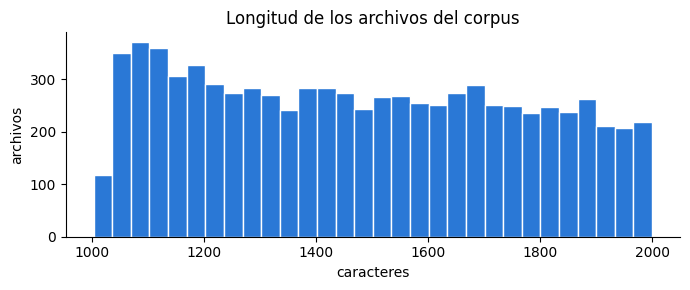

from contextlib import contextmanager
from datetime import datetime
from inspect import isclass

from celery import chord, group
from celery_once import QueueOnce
from celery.schedules import crontab
from celery.utils.log import get_task_logger
from sqlalchemy.orm.attributes import flag_modified

# from pipet import celery
from pipet.models import db, Organization
from pipet.sources.zendesk import ZendeskAccount
from pipet.sources.zendesk.models import (
    Base,
    CLASS_REGISTRY,
)


logger 


In [5]:
def es_python_valido(codigo):
    try:
        ast.parse(codigo)
        return True
    except (SyntaxError, ValueError, MemoryError, RecursionError):
        return False


chars = np.array([len(c) for c in corpus])
print(f"caracteres: media {chars.mean():.0f}, mediana {np.median(chars):.0f}")
print("duplicados exactos:", len(corpus) - len(set(corpus)))
print(f"archivos reales que pasan ast.parse: {100 * np.mean([es_python_valido(c) for c in corpus]):.1f} %")
print(f"con licencia o copyright al inicio: {100 * np.mean(['license' in c[:600].lower() or 'copyright' in c[:600].lower() for c in corpus]):.1f} %")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(chars, bins=30, color=AZUL, edgecolor="white", linewidth=1)
ax.set(title="Longitud de los archivos del corpus", xlabel="caracteres", ylabel="archivos")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(corpus[0][:500])

Como se puede observar, la longitud queda repartida en todo el rango permitido y una parte importante de los archivos empieza con una licencia. Esto importa porque esos encabezados se repiten mucho y los modelos los aprenden con facilidad. También hay que tener en cuenta que no todos los archivos reales pasan `ast.parse`: el corpus incluye código de Python 2, por ejemplo `print` sin paréntesis, que el analizador de Python 3 rechaza.

## 4. Preprocesamiento

El filtro de longitud ya se aplicó durante el streaming, así que aquí solo lo verificamos. Después tokenizamos cada archivo con el tokenizador de SmolLM2 y agregamos el token de fin para separar archivos al concatenarlos.

In [6]:
assert len(corpus) == N_EJEMPLOS and all(MIN_CHARS <= len(c) <= MAX_CHARS for c in corpus)

tok = AutoTokenizer.from_pretrained(TOKENIZER)
assert tok.vocab_size == VOCAB_SIZE
ids_archivos = [np.array(x + [tok.eos_token_id], dtype=np.int32) for x in tok(corpus, add_special_tokens=False)["input_ids"]]

lens = np.array([len(x) for x in ids_archivos])
print(f"tokens por archivo: media {lens.mean():.0f}, mediana {np.median(lens):.0f}, min {lens.min()}, max {lens.max()}")
print(f"tokens totales: {lens.sum()} | archivos con mas de {CONTEXT} tokens: {100 * (lens > CONTEXT).mean():.1f} %")


def make_blocks(file_ids, context=CONTEXT, offset=0, rng=None):
    """Concatena los archivos (en orden aleatorio si hay rng) y corta bloques de `context` tokens sin solape."""
    order = np.arange(len(file_ids)) if rng is None else rng.permutation(len(file_ids))
    stream = np.concatenate([file_ids[i] for i in order])[offset:]
    n = len(stream) // context
    return torch.from_numpy(stream[:n * context].reshape(n, context).astype(np.int64))

tokens por archivo: media 433, mediana 421, min 199, max 1358
tokens totales: 3461031 | archivos con mas de 256 tokens: 98.4 %


La segmentación en secuencias de 256 tokens se aplica en la sección 5, dentro de cada partición. Si concatenáramos todo el corpus antes de dividirlo, un mismo archivo podría quedar repartido entre entrenamiento y prueba.

## 5. Split train / validación / prueba

Hacemos la división 6.400 / 800 / 800 por archivo completo y con semilla fija. Luego segmentamos cada partición en bloques de 256 tokens. Los pocos tokens finales que no completan un bloque se descartan.

In [7]:
idx = np.random.default_rng(SEMILLA_SPLIT).permutation(len(corpus))
a, b = SPLITS[0], SPLITS[0] + SPLITS[1]
ids_train = [ids_archivos[i] for i in idx[:a]]
ids_valid = [ids_archivos[i] for i in idx[a:b]]
ids_test = [ids_archivos[i] for i in idx[b:b + SPLITS[2]]]
assert len(set(idx[:b + SPLITS[2]].tolist())) == sum(SPLITS)

bloques_valid = make_blocks(ids_valid)
bloques_test = make_blocks(ids_test)
bloques_monitor = bloques_valid[:MONITOR_BLOCKS]
n_train_blocks = len(make_blocks(ids_train))
print("archivos:", len(ids_train), len(ids_valid), len(ids_test))
print("bloques :", n_train_blocks, len(bloques_valid), len(bloques_test))

archivos: 6400 800 800
bloques : 10805 1358 1355


Validación se usa para monitorear el entrenamiento y elegir hiperparámetros. El conjunto de prueba solo se usa en la sección 8.

## 6. Modelo desde cero

Implementamos un GPT decoder-only en PyTorch. La atención multi-cabeza enmascarada está escrita a mano. Cada bloque usa normalización previa, conexiones residuales y una red feed-forward con GELU. Las posiciones son aprendidas, y la capa de salida comparte pesos con los embeddings de tokens.

In [8]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout, context):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head, self.head_dim = n_head, n_embd // n_head
        self.key_query_value = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.proj = nn.Linear(n_embd, n_embd, bias=False)
        self.attn_drop, self.resid_drop = nn.Dropout(dropout), nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(context, context, dtype=torch.bool)), persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        k, q, v = self.key_query_value(x).chunk(3, dim=-1)
        shape = (B, T, self.n_head, self.head_dim)
        k, q, v = [t.view(shape).transpose(1, 2) for t in (k, q, v)]           # (B, h, T, d)
        att = q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)
        att = att.masked_fill(~self.mask[:T, :T], float("-inf"))               # no mirar el futuro
        att = self.attn_drop(F.softmax(att, dim=-1))
        out = (att @ v).transpose(1, 2).reshape(B, T, C)
        return self.resid_drop(self.proj(out))


class Block(nn.Module):
    def __init__(self, n_embd, n_head, dropout, context):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, dropout, context)
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))          # pre-LN, como GPT-2
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    def __init__(self, n_layer, n_head, n_embd, dropout, context=CONTEXT, vocab_size=VOCAB_SIZE):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, n_embd)
        self.pos = nn.Embedding(context, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(n_embd, n_head, dropout, context) for _ in range(n_layer)])
        self.ln = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.head.weight = self.tok.weight
        self.apply(self._init)
        for name, p in self.named_parameters():                     # escala las salidas residuales (GPT-2)
            if name.endswith("attn.proj.weight") or name.endswith("mlp.2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * n_layer))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx):
        T = idx.size(1)
        x = self.drop(self.tok(idx) + self.pos(torch.arange(T, device=idx.device)))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln(x))


def logits_of(model, ids):
    """Logits (B, T, V) tanto para el GPT propio como para los modelos de Hugging Face."""
    out = model(ids)
    return out if torch.is_tensor(out) else out.logits


def count_params(model):
    return sum(p.numel() for p in {id(p): p for p in model.parameters()}.values())

La perplejidad se calcula a nivel de token: acumulamos $-\log p(x_i \mid x_{<i})$ sobre todos los tokens y dividimos una sola vez por $N$ antes de exponenciar. No promediamos por lote y no hay relleno porque todos los bloques tienen 256 tokens.

El siguiente bucle de entrenamiento es el mismo para el GPT y para los finetunings. Usa AdamW, calentamiento y decaimiento coseno, recorte de gradiente, precisión mixta y acumulación de gradiente. En cada época vuelve a cortar los bloques con un desplazamiento y un orden de archivos distintos, para que el modelo no vea siempre las mismas secuencias. Si la validación deja de mejorar durante varias evaluaciones, el entrenamiento se detiene.

In [9]:
@torch.no_grad()
def token_nll(model, blocks, device, batch_size=16, amp_dtype=None):
    """Suma de -log p(x_i | x_<i) sobre todos los tokens y numero de tokens evaluados."""
    model.eval()
    total, n = 0.0, 0
    for s in range(0, len(blocks), batch_size):
        b = blocks[s:s + batch_size].to(device)
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            logits = logits_of(model, b)
        nll = F.cross_entropy(logits[:, :-1].reshape(-1, logits.size(-1)).float(), b[:, 1:].reshape(-1), reduction="sum")
        total += nll.item()
        n += b[:, 1:].numel()
    return total, n


def perplexity(model, blocks, device, batch_size=16, amp_dtype=None):
    total, n = token_nll(model, blocks, device, batch_size, amp_dtype)
    return math.exp(total / n), total / n, n


def lr_at(step, total, warmup, base_lr):
    if step < warmup:
        return base_lr * (step + 1) / max(1, warmup)
    p = (step - warmup) / max(1, total - warmup)
    return base_lr * 0.5 * (1 + math.cos(math.pi * p))


def param_groups(model, weight_decay):
    """Sin weight decay en normas y sesgos."""
    groups, seen = {}, set()
    for name, p in model.named_parameters():
        if id(p) in seen or not p.requires_grad:
            continue
        seen.add(id(p))
        decays = p.dim() >= 2 and "ln" not in name.split(".")[-2:] and "norm" not in name
        key = weight_decay if decays else 0.0
        groups.setdefault(key, dict(params=[], weight_decay=key))["params"].append(p)
    return list(groups.values())


def train(model, train_ids, valid_blocks, device, cfg, on_best=None):
    amp_dtype, scaler = amp_setup(device)
    rng = np.random.default_rng(cfg["seed"])
    blocks0 = make_blocks(train_ids)
    micro, accum = cfg["micro_batch"], cfg["grad_accum"]
    updates_per_epoch = max(1, len(blocks0) // (micro * accum))
    total = int(math.ceil(cfg["epochs"] * updates_per_epoch))
    warmup = int(cfg["warmup_frac"] * total)
    opt = torch.optim.AdamW(param_groups(model, cfg["weight_decay"]), lr=cfg["lr"], betas=(0.9, 0.999))
    hist, step, best, best_step, bad = [], 0, float("inf"), 0, 0
    t0 = time.time()
    running, running_n = 0.0, 0
    stop = False
    opt.zero_grad(set_to_none=True)
    while step < total and not stop:
        blocks = make_blocks(train_ids, offset=int(rng.integers(0, CONTEXT)), rng=rng) if cfg["resegment"] else blocks0
        order = torch.from_numpy(rng.permutation(len(blocks)))
        for i in range(0, len(order) - micro + 1, micro):
            model.train()
            x = blocks[order[i:i + micro]].to(device)
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
                logits = logits_of(model, x)
                loss = F.cross_entropy(logits[:, :-1].reshape(-1, logits.size(-1)).float(), x[:, 1:].reshape(-1))
            running += loss.item()
            running_n += 1
            loss = loss / accum
            (scaler.scale(loss) if scaler else loss).backward()
            if (i // micro + 1) % accum:
                continue
            lr = lr_at(step, total, warmup, cfg["lr"])
            for g in opt.param_groups:
                g["lr"] = lr
            if scaler:
                scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            if scaler:
                scaler.step(opt)
                scaler.update()
            else:
                opt.step()
            opt.zero_grad(set_to_none=True)
            step += 1
            if step % cfg["eval_every"] == 0 or step == total:
                ppl, nll, _ = perplexity(model, valid_blocks, device, cfg["eval_batch"], amp_dtype)
                hist.append(dict(step=step, epoch=step / updates_per_epoch, train_loss=running / running_n, val_loss=nll,
                                 val_ppl=ppl, lr=lr, secs=time.time() - t0))
                print(f"step {step}/{total} ep {step / updates_per_epoch:.2f} train {running / running_n:.4f} "
                      f"val {nll:.4f} ppl {ppl:.3f} {time.time() - t0:.0f}s")
                running, running_n = 0.0, 0
                if nll < best - 1e-4:
                    best, best_step, bad = nll, step, 0
                    if on_best:
                        on_best(model)
                else:
                    bad += 1
                    if bad >= cfg["patience_evals"]:
                        print(f"parada temprana (mejor paso {best_step})")
                        stop = True
                        break
            if step >= total:
                break
    del opt
    return hist, best_step


def entrenar_con_mejor_estado(model, cfg):
    """Entrena y deja en el modelo los pesos del mejor paso de validacion."""
    updates = n_train_blocks // (cfg["micro_batch"] * cfg["grad_accum"])
    cfg = dict(cfg, eval_every=max(1, round(cfg["eval_frac"] * updates)))
    mejor = {}

    def guardar_mejor(m):
        mejor.update({k: v.detach().cpu().clone() for k, v in m.state_dict().items()})

    hist, best_step = train(model, ids_train, bloques_monitor, device, cfg, on_best=guardar_mejor)
    model.load_state_dict(mejor)
    return hist, best_step


def curvas(ax, hist, titulo, base=None):
    x = [h["epoch"] for h in hist]
    ax.plot(x, [h["train_loss"] for h in hist], color=AZUL, linewidth=2, label="entrenamiento")
    ax.plot(x, [h["val_loss"] for h in hist], color=NARANJA, linewidth=2, label="validación")
    if base is not None:
        ax.axhline(base, color=TINTA, linewidth=1, linestyle="--", label="validación antes del finetuning")
    ax.set(title=titulo, xlabel="época", ylabel="pérdida (nats por token)")
    ax.grid(axis="y", color=GRIS, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)

Antes de fijar la arquitectura hicimos experimentos en un notebook aparte, con el mismo código, porque tomaban varias horas de GPU. Primero probamos 12 variantes durante 2 épocas, y luego llevamos las mejores a más épocas. Todas las decisiones se tomaron con validación. La siguiente tabla resume las corridas, ordenadas de mejor a peor dentro de cada ronda.

| Corrida | Configuración | Perplejidad en validación |
|---|---|---:|
| R1a/g09_lr1e3 | 6 capas, 384 dim, lr 1e-03, dropout 0.1, 2 épocas | 29.235 |
| R1a/g08_lr6e4 | 6 capas, 384 dim, lr 6e-04, dropout 0.1, 2 épocas | 32.121 |
| R1a/g03_grande | 8 capas, 512 dim, lr 3e-04, dropout 0.1, 2 épocas | 34.921 |
| R1a/g04_ancho | 4 capas, 512 dim, lr 3e-04, dropout 0.1, 2 épocas | 36.410 |
| R1a/g07_drop00 | 6 capas, 384 dim, lr 3e-04, dropout 0.0, 2 épocas | 38.959 |
| R1a/g01_base | 6 capas, 384 dim, lr 3e-04, dropout 0.1, 2 épocas | 42.558 |
| R1a/g12_wd01 | 6 capas, 384 dim, lr 3e-04, dropout 0.1, 2 épocas, weight decay 0.1 | 42.717 |
| R1a/g11_sin_atar | 6 capas, 384 dim, lr 3e-04, dropout 0.1, 2 épocas, sin atar pesos | 43.052 |
| R1a/g06_drop02 | 6 capas, 384 dim, lr 3e-04, dropout 0.2, 2 épocas | 46.855 |
| R1a/g05_profundo | 10 capas, 256 dim, lr 3e-04, dropout 0.1, 2 épocas | 54.760 |
| R1a/g02_chico | 4 capas, 256 dim, lr 3e-04, dropout 0.1, 2 épocas | 58.990 |
| R1a/g10_sinusoidal | 6 capas, 384 dim, lr 3e-04, dropout 0.1, 2 épocas, posiciones sinusoidales | 518.421 |
| R1b/largo_g03_grande | 8 capas, 512 dim, lr 3e-04, dropout 0.1, 6 épocas | 16.123 |
| R1b/largo_g08_lr6e4 | 6 capas, 384 dim, lr 6e-04, dropout 0.1, 6 épocas | 16.509 |
| R1b/largo_g09_lr1e3 | 6 capas, 384 dim, lr 1e-03, dropout 0.1, 6 épocas | 16.721 |
| R1c/g14_grande_lr6e4 | 8 capas, 512 dim, lr 6e-04, dropout 0.1, 6 épocas | 15.155 |
| R1c/g13_sin_escala | 6 capas, 384 dim, lr 3e-04, dropout 0.1, 2 épocas, posiciones sinusoidales escala 0.028 | 40.840 |

De estos experimentos sacamos varias conclusiones. Aumentar la tasa de aprendizaje acelera mucho las primeras épocas: con 2 épocas, pasar de 3e-4 (`g01`) a 1e-3 (`g09`) bajó la perplejidad de 42.56 a 29.24. Con 6 épocas esa ventaja se reduce, y en el modelo de 6 capas casi no hay diferencia entre 6e-4 y 1e-3. El tamaño también ayuda: el modelo de 8 capas y 512 dimensiones fue el mejor, y al subir su tasa a 6e-4 (`g14`) pasó de 16.12 a 15.16. Las posiciones sinusoidales de `g10` fallaron porque su amplitud de ±1 es mucho mayor que la de los embeddings, que se inicializan con desviación 0.02. Al corregir la escala en `g13` quedaron al nivel de las posiciones aprendidas (40.84 frente a 42.56 de `g01`), así que mantuvimos las aprendidas.

Elegimos `g14`, la configuración con menor perplejidad en validación.

parametros: 50500608
step 135/4050 ep 0.20 train 7.2961 val 5.3648 ppl 213.749 24s
step 270/4050 ep 0.40 train 5.0244 val 4.6013 ppl 99.618 49s
step 405/4050 ep 0.60 train 4.3957 val 4.1234 ppl 61.772 75s
step 540/4050 ep 0.80 train 4.0442 val 3.8565 ppl 47.299 101s
step 675/4050 ep 1.00 train 3.8648 val 3.6613 ppl 38.910 129s
step 810/4050 ep 1.20 train 3.5201 val 3.5305 ppl 34.139 156s
step 945/4050 ep 1.40 train 3.4279 val 3.4238 ppl 30.685 182s
step 1080/4050 ep 1.60 train 3.3605 val 3.3275 ppl 27.868 209s
step 1215/4050 ep 1.80 train 3.2615 val 3.2246 ppl 25.143 236s
step 1350/4050 ep 2.00 train 3.1820 val 3.1469 ppl 23.263 262s
step 1485/4050 ep 2.20 train 2.8940 val 3.1011 ppl 22.222 289s
step 1620/4050 ep 2.40 train 2.8604 val 3.0508 ppl 21.132 316s
step 1755/4050 ep 2.60 train 2.7747 val 2.9960 ppl 20.005 342s
step 1890/4050 ep 2.80 train 2.7592 val 2.9425 ppl 18.964 369s
step 2025/4050 ep 3.00 train 2.6992 val 2.8917 ppl 18.024 395s
step 2160/4050 ep 3.20 train 2.4148 val 2.8

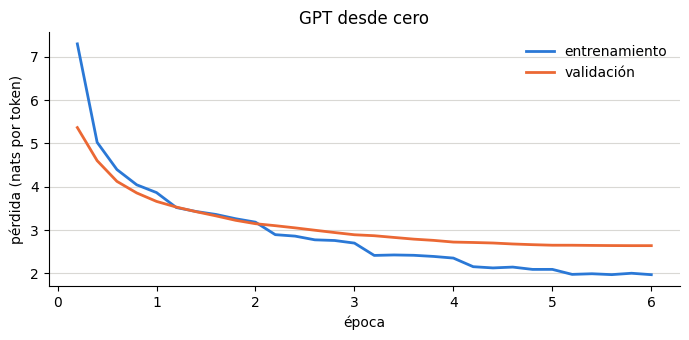

mejor paso 4050 | 13.3 min


In [10]:
ruta_gpt, ruta_hist_gpt = os.path.join(DIR_CKPT, "gpt_desde_cero.pt"), os.path.join(DIR_CKPT, "gpt_desde_cero_historial.json")

if os.path.exists(ruta_gpt) and os.path.exists(ruta_hist_gpt):
    print("checkpoint encontrado, no se reentrena")
    with open(ruta_hist_gpt, encoding="utf-8") as f:
        reg_gpt = json.load(f)
else:
    set_seed(ENT_GPT["seed"])
    model = GPT(**CFG_GPT).to(device)
    print("parametros:", count_params(model))
    t0 = time.time()
    hist, best_step = entrenar_con_mejor_estado(model, ENT_GPT)
    torch.save(dict(config=CFG_GPT, state_dict=model.state_dict()), ruta_gpt)
    reg_gpt = dict(hist=hist, best_step=best_step, minutos=(time.time() - t0) / 60)
    with open(ruta_hist_gpt, "w", encoding="utf-8") as f:
        json.dump(reg_gpt, f)
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

fig, ax = plt.subplots(figsize=(7, 3.5))
curvas(ax, reg_gpt["hist"], "GPT desde cero")
plt.tight_layout()
plt.show()
print(f"mejor paso {reg_gpt['best_step']} | {reg_gpt['minutos']:.1f} min")

Como se puede observar en la curva de costo, la pérdida de validación bajó durante las 6 épocas y el mejor paso fue el último, así que la parada temprana no se activó. Las cifras coinciden con las de la corrida `g14` de los experimentos, por lo que el entrenamiento se pudo reproducir con la misma semilla.

También se ve sobreajuste. Al final, la pérdida de entrenamiento es 1.97 y la de validación es 2.64, una diferencia de 0.67 nats por token. Esta diferencia podría ser algo mayor, porque la pérdida de entrenamiento se mide con dropout activo. Además, la curva de entrenamiento baja de golpe al empezar cada época, cuando el modelo vuelve a ver los mismos archivos, y esa caída no aparece en validación. Aun así, la validación nunca empeoró, de modo que el modelo guardado es el del último paso.

## 7. Finetuning de los modelos pre-entrenados

Hacemos un finetuning completo: se actualizan todos los parámetros de cada modelo, sin LoRA ni QLoRA. Para que quepa en la T4 combinamos tres técnicas:

- **Precisión mixta:** `torch.autocast` con fp16 y `GradScaler`. Los pesos maestros se mantienen en fp32. Usamos fp16 porque la T4 solo emula bf16 y resulta más lento.
- **Acumulación de gradiente:** micro-batch de 4 con 4 pasos acumulados, para un lote efectivo de 16.
- **Gradient checkpointing:** `gradient_checkpointing_enable()` con `use_cache = False`.

Entrenamos un modelo a la vez y liberamos la GPU antes de cargar el siguiente. Guardamos los pesos en bf16, el mismo formato de los modelos originales, para que el zip no sea tan pesado.

Primero hicimos un tamizado a media época y llevamos las mejores variantes a más épocas. La tabla resume esas corridas sobre validación.

| Corrida | Configuración | Perplejidad en validación |
|---|---|---:|
| R2a/f04_lr2e4 | lr 2e-04, 0.5 épocas, lote efectivo 16 | 5.150 |
| R2a/f06_constante | lr 5e-05, 0.5 épocas, lote efectivo 16, tasa constante | 5.178 |
| R2a/f03_lr1e4 | lr 1e-04, 0.5 épocas, lote efectivo 16 | 5.184 |
| R2a/f07_lote8 | lr 5e-05, 0.5 épocas, lote efectivo 8 | 5.229 |
| R2a/f05_lr4e4 | lr 4e-04, 0.5 épocas, lote efectivo 16 | 5.230 |
| R2a/f08_lote32 | lr 1e-04, 0.5 épocas, lote efectivo 32 | 5.238 |
| R2a/f01_lr5e5 | lr 5e-05, 0.5 épocas, lote efectivo 16 | 5.283 |
| R2a/f09_wd01 | lr 5e-05, 0.5 épocas, lote efectivo 16, weight decay 0.1 | 5.283 |
| R2a/f10_llrd | lr 1e-04, 0.5 épocas, lote efectivo 16, tasa por capa 0.9 | 5.433 |
| R2a/f02_lr2e5 | lr 2e-05, 0.5 épocas, lote efectivo 16 | 5.447 |
| R2b/largo_f04_lr2e4 | lr 2e-04, 2 épocas, lote efectivo 16 | 4.762 |
| R2b/largo_f03_lr1e4 | lr 1e-04, 2 épocas, lote efectivo 16 | 4.807 |
| R2b/largo_f06_constante | lr 5e-05, 2 épocas, lote efectivo 16, tasa constante | 4.824 |
| R3a/h03_lr1e4 | lr 1e-04, 0.5 épocas, lote efectivo 16 | 4.127 |
| R3a/h04_lr2e4 | lr 2e-04, 0.5 épocas, lote efectivo 16 | 4.146 |
| R3a/h02_lr6e5 | lr 6e-05, 0.5 épocas, lote efectivo 16 | 4.148 |
| R3a/h01_lr3e5 | lr 3e-05, 0.5 épocas, lote efectivo 16 | 4.203 |
| R3a/h05_atdrop01 | lr 1e-04, 0.5 épocas, lote efectivo 16, dropout de atención 0.1 | NaN, corrida fallida |

Como se puede observar, las tasas recomendadas por el enunciado funcionan, pero con este corpus una tasa algo mayor bajó más la perplejidad en los dos modelos: 2e-4 en el 135M y 1e-4 en el 360M. Dar 2 épocas también ayudó frente a media época. El weight decay de 0.1 no cambió el resultado, y la tasa por capa fue peor que usar la misma tasa en todo el modelo.

En el 360M solo corrimos el tamizado a media época para no gastar más tiempo de GPU, y dejamos las 2 épocas para este notebook. Probamos también un dropout de atención de 0.1 (`h05`), pero con fp16 la pérdida de entrenamiento dio NaN y el modelo casi no se actualizó. Esa corrida no es válida y no usamos esa opción.

In [11]:
def finetunear(nombre_hf, cfg, carpeta):
    ruta, ruta_hist = os.path.join(DIR_CKPT, carpeta), os.path.join(DIR_CKPT, carpeta + "_historial.json")
    if os.path.exists(os.path.join(ruta, "config.json")) and os.path.exists(ruta_hist):
        print(nombre_hf, ": checkpoint encontrado, no se reentrena")
        with open(ruta_hist, encoding="utf-8") as f:
            return json.load(f)
    set_seed(cfg["seed"])
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(nombre_hf).to(torch.float32)       # pesos maestros en fp32
    model.config.use_cache = False
    model.gradient_checkpointing_enable()
    model = model.to(device)
    print(nombre_hf, "| parametros:", count_params(model))
    _, base, _ = perplexity(model, bloques_monitor, device, cfg["eval_batch"], amp_dtype)
    t0 = time.time()
    hist, best_step = entrenar_con_mejor_estado(model, cfg)
    reg = dict(hist=hist, best_step=best_step, base=base, minutos=(time.time() - t0) / 60)
    if device.type == "cuda":
        reg["memoria_gb"] = torch.cuda.max_memory_allocated() / 2 ** 30
    model.config.use_cache = True
    model.gradient_checkpointing_disable()
    model.to(torch.bfloat16).save_pretrained(ruta)
    with open(ruta_hist, "w", encoding="utf-8") as f:
        json.dump(reg, f)
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return reg


reg_135 = finetunear(SMOL135, ENT_135, "smollm2_135m_finetuned")

HuggingFaceTB/SmolLM2-135M | parametros: 134515008
step 68/1350 ep 0.10 train 1.7349 val 1.7203 ppl 5.586 83s
step 136/1350 ep 0.20 train 1.6969 val 1.7006 ppl 5.477 168s
step 204/1350 ep 0.30 train 1.6804 val 1.6760 ppl 5.344 254s
step 272/1350 ep 0.40 train 1.6461 val 1.6543 ppl 5.229 339s
step 340/1350 ep 0.50 train 1.5845 val 1.6320 ppl 5.114 424s
step 408/1350 ep 0.60 train 1.5802 val 1.6165 ppl 5.035 508s
step 476/1350 ep 0.71 train 1.5508 val 1.6046 ppl 4.976 593s
step 544/1350 ep 0.81 train 1.5549 val 1.5855 ppl 4.882 679s
step 612/1350 ep 0.91 train 1.5761 val 1.5735 ppl 4.824 764s
step 680/1350 ep 1.01 train 1.5301 val 1.5640 ppl 4.778 849s
step 748/1350 ep 1.11 train 1.3212 val 1.5723 ppl 4.818 932s
step 816/1350 ep 1.21 train 1.3266 val 1.5599 ppl 4.758 1015s
step 884/1350 ep 1.31 train 1.3127 val 1.5548 ppl 4.734 1099s
step 952/1350 ep 1.41 train 1.2885 val 1.5489 ppl 4.707 1184s
step 1020/1350 ep 1.51 train 1.3132 val 1.5462 ppl 4.694 1270s
step 1088/1350 ep 1.61 train 1.

In [12]:
reg_360 = finetunear(SMOL360, ENT_360, "smollm2_360m_finetuned")

HuggingFaceTB/SmolLM2-360M | parametros: 361821120
step 68/1350 ep 0.10 train 1.4739 val 1.4628 ppl 4.318 140s
step 136/1350 ep 0.20 train 1.4401 val 1.4458 ppl 4.245 280s
step 204/1350 ep 0.30 train 1.4308 val 1.4249 ppl 4.157 421s
step 272/1350 ep 0.40 train 1.4070 val 1.4116 ppl 4.103 561s
step 340/1350 ep 0.50 train 1.3501 val 1.3993 ppl 4.052 701s
step 408/1350 ep 0.60 train 1.3534 val 1.3872 ppl 4.003 840s
step 476/1350 ep 0.71 train 1.3331 val 1.3771 ppl 3.963 980s
step 544/1350 ep 0.81 train 1.3368 val 1.3663 ppl 3.921 1120s
step 612/1350 ep 0.91 train 1.3637 val 1.3560 ppl 3.881 1260s
step 680/1350 ep 1.01 train 1.3224 val 1.3497 ppl 3.856 1400s
step 748/1350 ep 1.11 train 1.1508 val 1.3598 ppl 3.896 1540s
step 816/1350 ep 1.21 train 1.1571 val 1.3547 ppl 3.876 1678s
step 884/1350 ep 1.31 train 1.1406 val 1.3489 ppl 3.853 1817s
step 952/1350 ep 1.41 train 1.1231 val 1.3477 ppl 3.849 1957s
step 1020/1350 ep 1.51 train 1.1441 val 1.3442 ppl 3.835 2097s
step 1088/1350 ep 1.61 tra

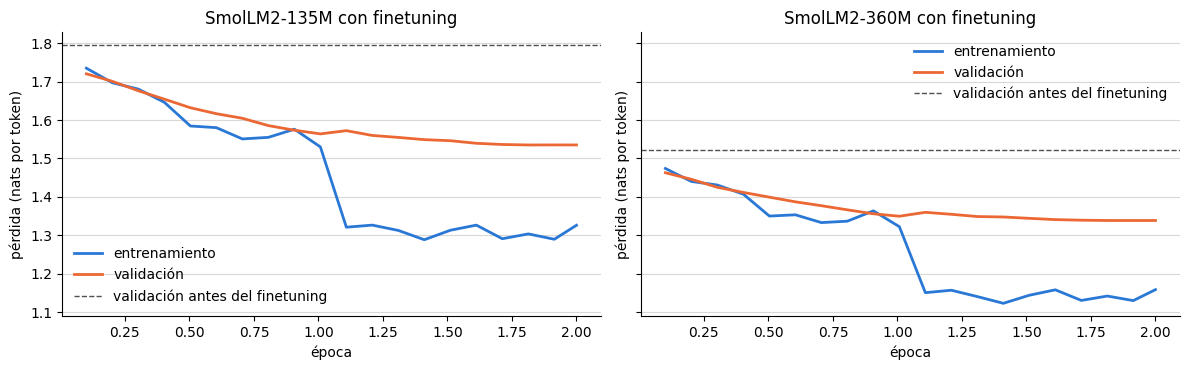

135M: mejor paso 1224 | 27.9 min | memoria 5.37 GB
360M: mejor paso 1224 | 46.3 min | memoria 7.91 GB


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
curvas(axes[0], reg_135["hist"], "SmolLM2-135M con finetuning", reg_135["base"])
curvas(axes[1], reg_360["hist"], "SmolLM2-360M con finetuning", reg_360["base"])
plt.tight_layout()
plt.show()
for nombre, reg in (("135M", reg_135), ("360M", reg_360)):
    print(f"{nombre}: mejor paso {reg['best_step']} | {reg['minutos']:.1f} min | memoria {reg.get('memoria_gb', 0):.2f} GB")

Los dos modelos mejoran desde la primera evaluación. Después del finetuning, la pérdida de validación sobre los bloques de monitoreo bajó de 1.795 a 1.535 en el 135M y de 1.523 a 1.339 en el 360M. En ambos casos el mejor paso fue el 1224 de 1350, porque al final la tasa es casi cero y los pesos ya casi no cambian.

En las curvas de costo se nota un salto al empezar la segunda época. La pérdida de entrenamiento cae de 1.53 a 1.32 en el 135M y de 1.32 a 1.15 en el 360M, mientras la de validación sube un poco, de 1.564 a 1.572 y de 1.350 a 1.360. Ahí aparece el sobreajuste, porque el modelo empieza a ver archivos que ya conoce. La validación se recupera cuando la tasa baja, pero la segunda época aporta poco: la perplejidad de monitoreo pasa de 4.778 a 4.642 en el 135M (2.8 % menos) y de 3.856 a 3.814 en el 360M (1.1 % menos). Al final, la diferencia entre entrenamiento y validación es cercana a 0.2 nats por token en los dos modelos.

Para controlar el sobreajuste usamos weight decay de 0.01, un nuevo corte de bloques en cada época, parada temprana con paciencia de 6 evaluaciones y restauración del mejor estado. La parada temprana no se activó porque la validación no empeoró de forma sostenida.

## 8. Evaluación y comparación

Evaluamos las cinco configuraciones sobre prueba, cargando los checkpoints desde el disco para medir exactamente lo que se entrega.

- **Perplejidad:** sobre los bloques de 256 tokens de los 800 archivos de prueba.
- **Validez sintáctica:** tomamos 200 archivos de prueba con semilla fija, usamos sus primeros 128 tokens como prompt y generamos 128 tokens más. Si la generación se corta por el límite de tokens, descartamos la última línea antes de pasar `ast.parse`.

El muestreo principal es temperatura 0.7 con top-p 0.9. Lo elegimos con validación sobre una grilla de siete opciones: la selección voraz daba la mayor validez, pero repetía muchas líneas, y temperaturas más altas perdían validez. También reportamos la selección voraz para ver qué tanto depende la métrica del muestreo.

Como referencia, medimos también el código real cortado a la misma longitud. Esto ayuda a interpretar la métrica, porque cortar un archivo a 256 tokens suele dejar bloques abiertos.

In [14]:
def filter_logits(logits, top_k=0, top_p=1.0):
    if top_k:
        kth = torch.topk(logits, top_k, dim=-1).values[..., -1, None]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if top_p < 1.0:
        sorted_logits, order = torch.sort(logits, descending=True, dim=-1)
        cum = F.softmax(sorted_logits, dim=-1).cumsum(dim=-1)
        drop = cum > top_p
        drop[..., 1:] = drop[..., :-1].clone()
        drop[..., 0] = False
        logits = logits.masked_fill(drop.scatter(-1, order, drop), float("-inf"))
    return logits


@torch.no_grad()
def generate(model, prompt_ids, max_new_tokens, device, eos_id, temperature=0.8, top_k=50, top_p=1.0, seed=0,
             amp_dtype=None, context=CONTEXT):
    """Bucle autorregresivo en lote: logits -> distribucion -> muestreo -> concatenar al contexto.

    prompt_ids: tensor (B, P) con prefijos de igual longitud. Devuelve (ids, longitudes, termino_por_eos).
    En los modelos de Hugging Face se reutiliza el KV-cache mientras la secuencia quepa en el contexto; el
    GPT propio vuelve a procesar la ventana de los ultimos `context` tokens en cada paso.
    """
    model.eval()
    gen = torch.Generator(device=device).manual_seed(seed)
    ids = prompt_ids.to(device)
    B = ids.size(0)
    done = torch.zeros(B, dtype=torch.bool, device=device)
    lengths = torch.full((B,), ids.size(1) + max_new_tokens, device=device)
    cached = hasattr(model, "config") and ids.size(1) + max_new_tokens <= context
    past = None
    for _ in range(max_new_tokens):
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            if cached:
                out = model(input_ids=ids if past is None else ids[:, -1:], past_key_values=past, use_cache=True)
                logits, past = out.logits[:, -1].float(), out.past_key_values
            else:
                logits = logits_of(model, ids[:, -context:])[:, -1].float()
        if temperature <= 0:
            nxt = logits.argmax(-1)
        else:
            probs = F.softmax(filter_logits(logits / temperature, top_k, top_p), dim=-1)
            nxt = torch.multinomial(probs, 1, generator=gen).squeeze(1)
        nxt = nxt.masked_fill(done, eos_id)
        ids = torch.cat([ids, nxt[:, None]], dim=1)
        new_done = (~done) & (nxt == eos_id)
        lengths[new_done] = ids.size(1) - 1
        done |= new_done
        if bool(done.all()):
            break
    return ids.cpu(), lengths.cpu(), done.cpu()


def strip_truncated_line(code):
    """Descarta la ultima linea cuando la generacion fue cortada por el limite de tokens."""
    return code.rsplit("\n", 1)[0] if "\n" in code else ""


def syntax_validity(model, tokenizer, files_ids, device, n=200, prompt_tokens=128, new_tokens=128, seed=0, amp_dtype=None,
                    batch_size=32, **sampling):
    """Porcentaje de continuaciones sintacticamente validas sobre n archivos (semilla fija)."""
    rng = np.random.default_rng(seed)
    pool = [f for f in files_ids if len(f) > prompt_tokens + 1]
    chosen = rng.choice(len(pool), size=min(n, len(pool)), replace=False)
    prompts = torch.tensor(np.stack([pool[i][:prompt_tokens] for i in chosen]).astype(np.int64))
    valid, texts = [], []
    for s in range(0, len(prompts), batch_size):
        ids, lengths, done = generate(model, prompts[s:s + batch_size], new_tokens, device, tokenizer.eos_token_id,
                                      seed=seed + s, amp_dtype=amp_dtype, **sampling)
        for row, L, d in zip(ids, lengths, done):
            code = tokenizer.decode(row[:int(L)].tolist(), skip_special_tokens=True)
            if not d:
                code = strip_truncated_line(code)
            valid.append(es_python_valido(code))
            texts.append(code)
    return 100 * float(np.mean(valid)), texts


def reference_validity(tokenizer, files_ids, n=200, total_tokens=256, seed=0):
    """Codigo REAL cortado en la misma longitud, con el mismo tratamiento."""
    rng = np.random.default_rng(seed)
    pool = [f for f in files_ids if len(f) > total_tokens // 2 + 1]
    chosen = rng.choice(len(pool), size=min(n, len(pool)), replace=False)
    out = []
    for i in chosen:
        f = pool[i][:total_tokens]
        code = tokenizer.decode(f.tolist(), skip_special_tokens=True)
        if f[-1] != tokenizer.eos_token_id:
            code = strip_truncated_line(code)
        out.append(es_python_valido(code))
    return 100 * float(np.mean(out))


def wilson(pct, n, z=1.96):
    """Intervalo de confianza de Wilson al 95 % para un porcentaje medido sobre n ejemplos."""
    p = pct / 100
    centro = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    ancho = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (centro - ancho), 100 * (centro + ancho)


def errores_comunes(textos, k=3):
    conteo = Counter()
    for t in textos:
        try:
            ast.parse(t)
        except (SyntaxError, ValueError) as e:
            conteo[getattr(e, "msg", str(e)).split(". ")[0]] += 1
    return conteo.most_common(k)


def cargar_modelo(fuente):
    if fuente == "gpt":
        ckpt = torch.load(ruta_gpt, map_location="cpu")
        model = GPT(**ckpt["config"])
        model.load_state_dict(ckpt["state_dict"])
        return model.to(device)
    return AutoModelForCausalLM.from_pretrained(fuente).to(torch.float32).to(device)


CONFIGS = [("GPT desde cero", "gpt"),
           ("135M pre-entrenado", SMOL135),
           ("135M con finetuning", os.path.join(DIR_CKPT, "smollm2_135m_finetuned")),
           ("360M pre-entrenado", SMOL360),
           ("360M con finetuning", os.path.join(DIR_CKPT, "smollm2_360m_finetuned"))]

In [15]:
resultados = {}
for nombre, fuente in CONFIGS:
    t0 = time.time()
    model = cargar_modelo(fuente)
    ppl, nll, n = perplexity(model, bloques_test, device, 32, amp_dtype)
    ppl_val, _, _ = perplexity(model, bloques_valid, device, 32, amp_dtype)
    valida, textos = syntax_validity(model, tok, ids_test, device, n=N_VALIDEZ, prompt_tokens=PROMPT_TOKENS,
                                     new_tokens=NUEVOS_TOKENS, amp_dtype=amp_dtype, **MUESTREO)
    voraz, _ = syntax_validity(model, tok, ids_test, device, n=N_VALIDEZ, prompt_tokens=PROMPT_TOKENS,
                               new_tokens=NUEVOS_TOKENS, amp_dtype=amp_dtype, temperature=0.0)
    resultados[nombre] = dict(ppl=ppl, nll=nll, ppl_val=ppl_val, n=n, valida=valida, voraz=voraz, errores=errores_comunes(textos))
    print(f"{nombre}: {time.time() - t0:.0f} s")
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

referencia = reference_validity(tok, ids_test, n=N_VALIDEZ, total_tokens=PROMPT_TOKENS + NUEVOS_TOKENS)
with open(os.path.join(DIR_CKPT, "resultados_prueba.json"), "w", encoding="utf-8") as f:
    json.dump(dict(resultados=resultados, referencia=referencia), f, indent=1)

print(f"\n{'Configuracion':<22}{'PPL prueba':>11}{'NLL':>8}{'PPL valid.':>11}{'Validez %':>11}{'IC 95 %':>15}{'Voraz %':>9}")
for nombre, r in resultados.items():
    lo, hi = wilson(r["valida"], N_VALIDEZ)
    print(f"{nombre:<22}{r['ppl']:>11.3f}{r['nll']:>8.4f}{r['ppl_val']:>11.3f}{r['valida']:>11.1f}{f'{lo:.1f}-{hi:.1f}':>15}{r['voraz']:>9.1f}")
print(f"{'Codigo real cortado':<22}{'':>11}{'':>8}{'':>11}{referencia:>11.1f}")
print("\ntokens evaluados en prueba:", resultados["GPT desde cero"]["n"])
for nombre, r in resultados.items():
    print(f"errores mas comunes, {nombre}: {r['errores']}")

GPT desde cero: 120 s
135M pre-entrenado: 138 s
135M con finetuning: 137 s
360M pre-entrenado: 190 s
360M con finetuning: 189 s

Configuracion          PPL prueba     NLL PPL valid.  Validez %        IC 95 %  Voraz %
GPT desde cero             14.662  2.6853     15.155       50.0      43.1-56.9     58.5
135M pre-entrenado          6.016  1.7945      5.962       63.0      56.1-69.4     70.5
135M con finetuning         4.676  1.5425      4.764       62.0      55.1-68.4     65.0
360M pre-entrenado          4.601  1.5263      4.580       60.5      53.6-67.0     70.5
360M con finetuning         3.854  1.3492      3.906       57.5      50.6-64.1     62.5
Codigo real cortado                                        58.0

tokens evaluados en prueba: 345525
errores mas comunes, GPT desde cero: [("'(' was never closed", 17), ('invalid syntax', 8), ("'[' was never closed", 7)]
errores mas comunes, 135M pre-entrenado: [("'(' was never closed", 6), ('unterminated triple-quoted string literal (detecte

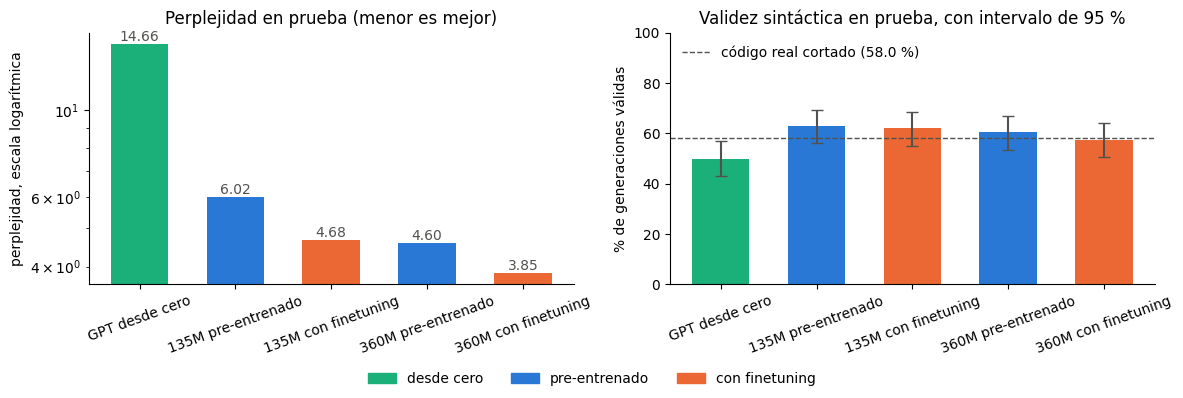

135M: finetuning cambia la perplejidad en -22.3 %
360M: finetuning cambia la perplejidad en -16.2 %
360M frente a 135M con finetuning: -17.6 %
360M con finetuning frente al GPT desde cero: -73.7 %


In [16]:
nombres = list(resultados)
colores = [AQUA, AZUL, NARANJA, AZUL, NARANJA]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(nombres, [resultados[k]["ppl"] for k in nombres], color=colores, width=0.6)
axes[0].set_yscale("log")
axes[0].set(title="Perplejidad en prueba (menor es mejor)", ylabel="perplejidad, escala logarítmica")
for i, k in enumerate(nombres):
    axes[0].annotate(f"{resultados[k]['ppl']:.2f}", (i, resultados[k]["ppl"]), ha="center", va="bottom", color=TINTA)

medias = [resultados[k]["valida"] for k in nombres]
lim = [wilson(m, N_VALIDEZ) for m in medias]
err = [[m - l for m, (l, h) in zip(medias, lim)], [h - m for m, (l, h) in zip(medias, lim)]]
axes[1].bar(nombres, medias, color=colores, width=0.6, yerr=err, ecolor=TINTA, capsize=4)
axes[1].axhline(referencia, color=TINTA, linewidth=1, linestyle="--", label=f"código real cortado ({referencia:.1f} %)")
axes[1].set(title="Validez sintáctica en prueba, con intervalo de 95 %", ylabel="% de generaciones válidas", ylim=(0, 100))
axes[1].legend(frameon=False, loc="upper left")

for ax in axes:
    ax.tick_params(axis="x", labelrotation=20)
    ax.spines[["top", "right"]].set_visible(False)
leyenda = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (AQUA, AZUL, NARANJA)]
fig.legend(leyenda, ["desde cero", "pre-entrenado", "con finetuning"], frameon=False, ncol=3, loc="lower center")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

def cambio(a, b):
    return 100 * (resultados[b]["ppl"] / resultados[a]["ppl"] - 1)

print(f"135M: finetuning cambia la perplejidad en {cambio('135M pre-entrenado', '135M con finetuning'):.1f} %")
print(f"360M: finetuning cambia la perplejidad en {cambio('360M pre-entrenado', '360M con finetuning'):.1f} %")
print(f"360M frente a 135M con finetuning: {cambio('135M con finetuning', '360M con finetuning'):.1f} %")
print(f"360M con finetuning frente al GPT desde cero: {cambio('GPT desde cero', '360M con finetuning'):.1f} %")

**Pre-entrenado frente a finetuning.** El finetuning bajó la perplejidad en prueba de 6.016 a 4.676 en el 135M (22.3 % menos) y de 4.601 a 3.854 en el 360M (16.2 % menos). La mejora relativa es mayor en el 135M, que partía de un valor más alto.

**135M frente a 360M.** Con finetuning, el 360M queda 17.6 % por debajo del 135M, así que el tamaño sigue contando después de especializar los modelos. Hay que tener en cuenta que el 360M sin entrenar (4.601) queda al nivel del 135M con finetuning (4.676). La siguiente tabla resume el costo de cada opción.

| | GPT desde cero | SmolLM2-135M | SmolLM2-360M |
|---|---:|---:|---:|
| Parámetros (millones) | 50.5 | 134.5 | 361.8 |
| Perplejidad inicial en prueba | no aplica | 6.016 | 4.601 |
| Perplejidad final en prueba | 14.662 | 4.676 | 3.854 |
| Tiempo de entrenamiento (min) | 13.3 | 27.9 | 46.3 |
| Memoria máxima de GPU (GB) | 4.7 | 5.4 | 7.9 |

La memoria del GPT es la medida en el experimento `g14`, que usa la misma configuración.

**Curvas de costo.** Las curvas de las secciones 6 y 7 muestran la diferencia entre partir de cero y partir de un modelo pre-entrenado. El GPT arranca con una pérdida de entrenamiento de 7.30 y su validación sigue bajando hasta el último paso, donde llega a 2.64. Los SmolLM2 ya parten de 1.795 y 1.523 en validación, y en la segunda época casi se aplanan: la perplejidad de monitoreo solo mejora 2.8 % en el 135M y 1.1 % en el 360M. La diferencia final entre entrenamiento y validación también es menor en los SmolLM2, cerca de 0.2 nats por token frente a 0.67 en el GPT.

**GPT desde cero.** Llegó a 14.662, lejos de los modelos pre-entrenados: incluso el 135M sin finetuning lo supera con 6.016. Con 6.400 archivos no alcanza para aprender desde cero lo que esos modelos traen de su entrenamiento previo.

**Validación frente a prueba.** Las dos perplejidades quedaron cerca en las cinco configuraciones, con una diferencia máxima de 3.3 %. No vemos señales de haber sobreajustado los hiperparámetros a validación.

**Validez sintáctica.** Con el muestreo principal, el GPT obtuvo 50.0 % y los cuatro SmolLM2 quedaron entre 57.5 % y 63.0 %. Sus intervalos se traslapan, así que con 200 ejemplos no se pueden separar. El código real cortado a la misma longitud da 58.0 %, por lo que estos valores hay que leerlos frente a esa referencia y no frente a 100 %.

El finetuning no mejoró la validez. Con selección voraz incluso bajó, de 70.5 % a 65.0 % en el 135M y de 70.5 % a 62.5 % en el 360M, aunque esos intervalos también se traslapan. El error más común en todos los modelos es un paréntesis sin cerrar, y es más frecuente con finetuning: pasa de 6 a 15 casos en el 135M y de 12 a 17 en el 360M. Una explicación posible, que no comprobamos, es que los modelos con finetuning imitan más el corpus, con llamadas y estructuras largas que quedan abiertas al llegar al límite de tokens. También aparecen errores de `print` sin paréntesis, propios del código Python 2 del corpus. Esto muestra que la perplejidad y la validez miden cosas distintas: un modelo puede predecir mejor el siguiente token sin generar más código que pase `ast.parse`.

## 9. Generación de ejemplos

La siguiente función genera código a partir de un prompt con un bucle autorregresivo escrito a mano, sin `model.generate()`. En cada paso obtiene los logits del modelo, los transforma en una distribución con temperatura y top-p, muestrea el siguiente token y lo concatena al contexto. La función `generate` de la sección 8 sigue la misma idea, pero procesa varios prompts en lote para que la validez no tarde tanto.

In [17]:
@torch.no_grad()
def generar_texto(model, prompt, max_nuevos=160, temperatura=0.7, top_p=0.9, semilla=0):
    model.eval()
    azar = torch.Generator(device=device).manual_seed(semilla)
    ids = torch.tensor([tok(prompt, add_special_tokens=False)["input_ids"]], device=device)
    cerro = False
    for _ in range(max_nuevos):
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=amp_dtype is not None):
            logits = logits_of(model, ids[:, -CONTEXT:])[:, -1].float()
        probs = F.softmax(filter_logits(logits / temperatura, 0, top_p), dim=-1)
        siguiente = torch.multinomial(probs, 1, generator=azar)
        if siguiente.item() == tok.eos_token_id:
            cerro = True
            break
        ids = torch.cat([ids, siguiente], dim=1)
    return tok.decode(ids[0].tolist(), skip_special_tokens=True), cerro


PROMPTS = ['def fibonacci(n):\n    """Return the n-th Fibonacci number."""\n',
           'class Stack(object):\n    """A simple stack."""\n\n    def __init__(self):\n',
           'import os\nimport sys\n\n\ndef main():\n']

for nombre, fuente in [CONFIGS[0], CONFIGS[2], CONFIGS[4]]:
    model = cargar_modelo(fuente)
    for j, prompt in enumerate(PROMPTS):
        texto, cerro = generar_texto(model, prompt, semilla=j)
        revisado = texto if cerro else strip_truncated_line(texto)
        print(f"=== {nombre} | ejemplo {j + 1} | ast.parse: {'valido' if es_python_valido(revisado) else 'invalido'}")
        print(texto)
        print()
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

=== GPT desde cero | ejemplo 1 | ast.parse: invalido
def fibonacci(n):
    """Return the n-th Fibonacci number."""

class TestInstance(unittest.TestCase):
    """Turn the median, we can be used for each point in a
    """
    def test_small(self):
        """Get a random algorithm."""
        self.n = n.i + 10 + 10000
        self.n = n.i + 1000
        self.n = n.n
        self.n = n.i + 10
        self.n = n.i + 10
        self.n = n.n
        self.n = n.n * 100000000000
        self.n = n - self.n * n - 0

    def test_basic(self):
       

=== GPT desde cero | ejemplo 2 | ast.parse: invalido
class Stack(object):
    """A simple stack."""

    def __init__(self):
	"""
		Convenience is non-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-to-
"""

from __future__ import unicode_literals

import os

from django.utils.translation import ugettext_lazy as _

from horizon import tabs

from openstack_dashboard.admin import 

Ahora revisamos los ejemplos. El GPT desde cero imita bien el formato del código: imports, clases, docstrings y funciones. Sin embargo, pierde el hilo rápido. En el primer ejemplo pasa del prompt a una clase de pruebas sin relación, en el segundo repite la misma secuencia de tokens y en el tercero define `main` varias veces.

Los modelos con finetuning mantienen mejor la coherencia. El 135M escribe una pila con `push`, `pop` y `empty`, y el 360M agrega docstrings y revisa si la pila está vacía antes de sacar un elemento. También se ven sus limitaciones. En el ejemplo de Fibonacci ninguno de los dos escribe el cuerpo de la función: los dos saltan a un `main`, aunque el 360M sí la llama por su nombre. Además, el `peek` del 135M usa `pop`, que no es correcto porque saca el elemento de la pila.

Ocho de los nueve ejemplos no pasan `ast.parse`. Revisamos el primer error de cada uno: tres son `print` sin paréntesis de Python 2, tres mezclan tabulaciones con los espacios del prompt, algo que Python 3 rechaza, y dos quedan con un `def` o un `if` sin cuerpo al descartar la última línea. Como se trata de pocos ejemplos, esto solo ilustra el comportamiento de los modelos. La medida general de validez es la de la sección 8.

## 10. Conclusiones

### Resultados

La mejor configuración fue SmolLM2-360M con finetuning, con perplejidad 3.854 en prueba. El finetuning mejoró los dos modelos pre-entrenados, 22.3 % en el 135M y 16.2 % en el 360M, y el modelo más grande fue mejor que el pequeño en ambos casos. El GPT desde cero llegó a 14.662, lejos de los modelos pre-entrenados.

Probar varias opciones ayudó. En el GPT, pasar de la configuración base (42.56 en validación, 2 épocas) a 8 capas, tasa 6e-4 y 6 épocas dejó la perplejidad en 15.16. En los SmolLM2, las tasas algo mayores que las sugeridas dieron mejores resultados: a media época, de 5.283 a 5.150 en el 135M y de 4.203 a 4.127 en el 360M.

La validez sintáctica no siguió el orden de la perplejidad. Los cuatro SmolLM2 no se pueden separar con 200 ejemplos y están cerca del 58.0 % del código real cortado. El GPT quedó de último con 50.0 %.

### Sobreajuste

Los tres modelos entrenados muestran sobreajuste al final: la pérdida de entrenamiento queda 0.67 nats por debajo de la de validación en el GPT y cerca de 0.2 en los SmolLM2. Sin embargo, la validación no empeoró de forma sostenida y prueba quedó cerca de validación. Las acciones que tomamos para controlarlo fueron:

- Dividir por archivo completo, para que un archivo no quede repartido entre particiones.
- Elegir los hiperparámetros solo con validación y usar prueba únicamente en la evaluación final.
- Usar dropout de 0.1 en el GPT y weight decay de 0.01 con AdamW, sin aplicarlo a normas y sesgos.
- Volver a cortar los bloques en cada época, con otro desplazamiento y otro orden de archivos.
- Usar parada temprana y restaurar los pesos del mejor paso de validación.

En los SmolLM2 la diferencia se abre al empezar la segunda época, y esa época aportó poco. Por eso creemos que más épocas no ayudarían mucho con este corpus. En el GPT la diferencia es mayor, y probablemente más datos ayudarían más que más épocas.

### Limitaciones

- Trabajamos con 8.000 archivos cortos. La división es por archivo y no por repositorio, así que archivos de un mismo proyecto pueden quedar en entrenamiento y en prueba.
- Con 200 ejemplos, la validez tiene un margen cercano a 7 puntos. Además, `ast.parse` rechaza código de Python 2 que sí es correcto en esa versión, y no mide si el código hace lo que pide el prompt, como se vio con Fibonacci.
- Los SmolLM2 se entrenaron sin dropout. Probamos dropout de atención en el 360M, pero la corrida dio NaN con fp16 y no investigamos la causa.
- En el 360M solo comparamos tasas a media época. La corrida de 2 épocas se hizo una sola vez, con la tasa elegida.
- Usamos una sola semilla, así que diferencias pequeñas, como la de 1e-4 y 2e-4 en el 360M, pueden deberse al azar.

### Referencias

- Vaswani, A. et al. (2017). Attention Is All You Need. NeurIPS.
- Radford, A. et al. (2019). Language Models are Unsupervised Multitask Learners. OpenAI.
- Tarjetas de los modelos `HuggingFaceTB/SmolLM2-135M` y `HuggingFaceTB/SmolLM2-360M`, y del dataset `codeparrot/codeparrot-clean`, en Hugging Face.